In [7]:
import pandas as pd
df = pd.read_excel("./../data/observaciones_02_03_2026.xlsx")
fecha = df["fecha"].dropna()
estacion_temp = df["estacion_temp"].dropna()
sensor_temp = df["sensor_temp"].dropna()

In [8]:
df.head()

,fecha,estacion_temp,estacion_hum,sensor_temp,sensor_hum,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48
0,2026-10-02 14:24:52,21.4,73.2,23.1,66.0,NaN,NaN,NaN,NaN,NaN,...,NaN,SUMMARY OUTPUT HUMEDAD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-02 14:29:52,21.3,73.6,24.1,64.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-02 14:34:52,21.2,73.1,23.9,63.0,NaN,NaN,NaN,NaN,NaN,...,NaN,Regression Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-02 14:39:52,21.5,72.5,23.5,65.0,NaN,NaN,NaN,NaN,NaN,...,NaN,Multiple R,0.781783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-02 14:44:52,21.4,72.8,25.9,59.0,NaN,NaN,NaN,NaN,NaN,...,NaN,R Square,0.611185,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Periodo observado: del 2026-10-02 14:24:52 al 2026-10-03 14:24:55

In [4]:
# Calcular el periodo observado
fecha_inicio = fecha.min()
fecha_fin = fecha.max()

print(f"Periodo observado: del {fecha_inicio.strftime('%Y-%m-%d %H:%M:%S')} al {fecha_fin.strftime('%Y-%m-%d %H:%M:%S')}")

Periodo observado: del 2026-10-02 14:24:52 al 2026-10-03 14:24:55


In [12]:
ultimos = estacion_temp.head(16)
# print(f"Valores analizados: \n{ultimos[0:5]}")
# val_esperado = ultimos[-1:]
# print(f"Valor Esperado: {val_esperado}")

# ultimos = estacion_temp.tail(30)
# print(f"Valores analizados: \n{ultimos[0:30]}")
# val_esperado = ultimos[-1:]
# print(f"Valor Esperado: {val_esperado}")

# TODOS LOS VALORES
# ultimos = estacion_temp
ultimos

0     21.4
1     21.3
2     21.2
3     21.5
4     21.4
5     21.0
6     20.2
7     19.6
8     19.8
9     20.0
10    19.7
11    19.5
12    19.6
13    20.0
14    20.1
15    20.3
Name: estacion_temp, dtype: float64

Serie original X^(0):
[21.4 21.3 21.2 21.5 21.4 21.  20.2 19.6 19.8 20.  19.7 19.5 19.6 20.
 20.1 20.3]

Serie acumulada X^(1):
[ 21.4  42.7  63.9  85.4 106.8 127.8 148.  167.6 187.4 207.4 227.1 246.6
 266.2 286.2 306.3 326.6]

Secuencia Z^(1):
[ 32.05  53.3   74.65  96.1  117.3  137.9  157.8  177.5  197.4  217.25
 236.85 256.4  276.2  296.25 316.45]

PARÁMETROS GM(1,1)
a = 0.0059499712
b = 21.3952102623

Predicción GM(1,1):
[21.4        21.20473454 21.07894158 20.95389487 20.82958997 20.70602248
 20.58318804 20.46108229 20.3397009  20.21903959 20.09909407 19.97986011
 19.86133349 19.74350999 19.62638547 19.50995576]

RESIDUOS DEL GM(1,1)
[ 0.09526546  0.12105842  0.54610513  0.57041003  0.29397752 -0.38318804
 -0.86108229 -0.5397009  -0.21903959 -0.39909407 -0.47986011 -0.26133349
  0.25649001  0.47361453  0.79004424]

PARÁMETROS DE FOURIER
T = 15
z = 6

Matriz P:
[[ 5.00000000e-01  6.69130606e-01  7.43144825e-01 -1.04528463e-01
   9.94521895e-01 -8.09016994e-01  5.87785252e-01 -9.781

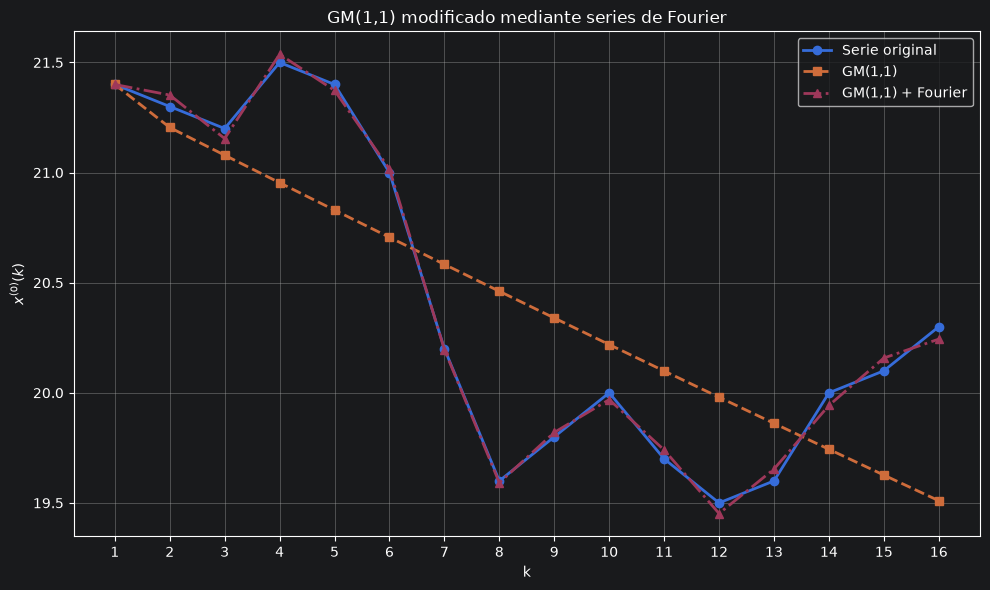

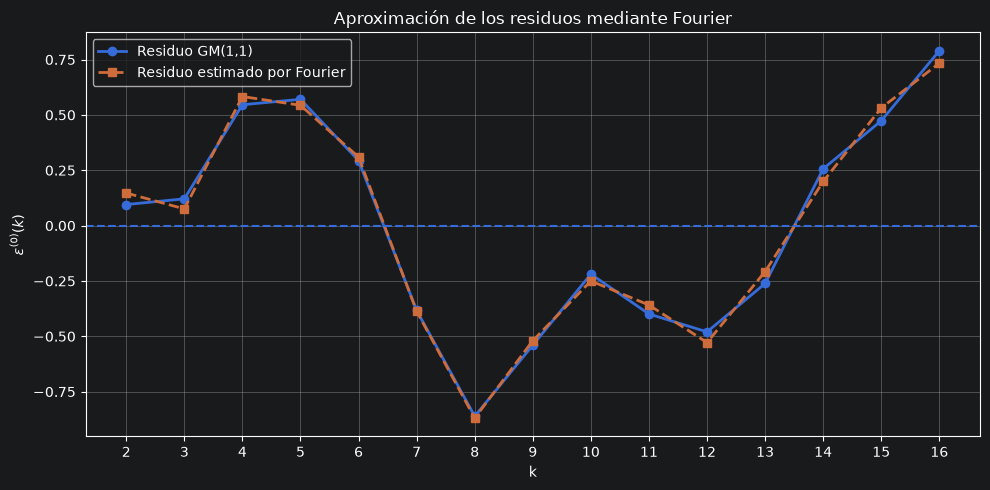

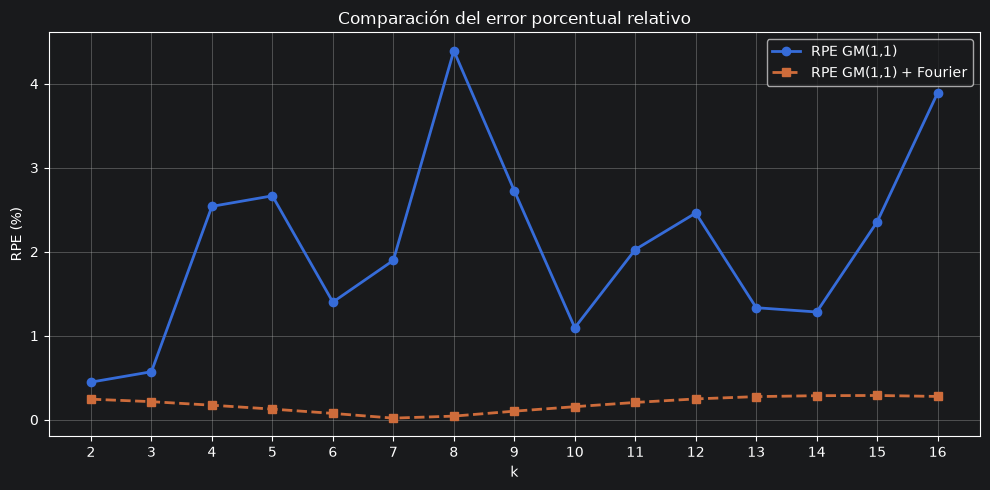

In [13]:
    # ============================================================
    # GM(1,1) MODIFICADO MEDIANTE SERIES DE FOURIER
    # Corrección de los residuos del error
    # Ecuaciones (22) - (30)
    # ============================================================

    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt


    # ============================================================
    # 1. SERIE ORIGINAL X^(0)
    # ============================================================

    X0 = ultimos.to_numpy(dtype=float)


    n = len(X0)

    print("Serie original X^(0):")
    print(X0)


    # ============================================================
    # 2. AGO
    #
    # X^(1)(k) = sum X^(0)(i)
    # ============================================================

    X1 = np.cumsum(X0)

    print("\nSerie acumulada X^(1):")
    print(X1)


    # ============================================================
    # 3. SECUENCIA DE VALORES MEDIOS Z^(1)
    #
    # z^(1)(k) =
    # 0.5*x^(1)(k) + 0.5*x^(1)(k-1)
    # ============================================================

    Z1 = 0.5 * (X1[1:] + X1[:-1])

    print("\nSecuencia Z^(1):")
    print(Z1)


    # ============================================================
    # 4. CONSTRUIR B Y Y
    # ============================================================

    B = np.column_stack((
        -Z1,
        np.ones(n - 1)
    ))

    Y = X0[1:].reshape(-1, 1)


    # ============================================================
    # 5. ESTIMAR a Y b
    # ============================================================

    parametros = np.linalg.lstsq(
        B,
        Y,
        rcond=None
    )[0]

    a = parametros[0, 0]
    b = parametros[1, 0]

    print("\n========================================")
    print("PARÁMETROS GM(1,1)")
    print("========================================")

    print(f"a = {a:.10f}")
    print(f"b = {b:.10f}")


    # ============================================================
    # 6. PREDICCIÓN GM(1,1)
    #
    # Ecuación (22)
    #
    # x_p^(0)(k+1) =
    #
    # [x^(0)(1)-b/a] exp(-ak)(1-exp(a))
    # ============================================================

    k_modelo = np.arange(1, n)

    X0_pred_restante = (
        (X0[0] - b/a)
        * np.exp(-a * k_modelo)
        * (1 - np.exp(a))
    )

    # Primer dato = condición inicial
    X0_pred = np.concatenate((
        [X0[0]],
        X0_pred_restante
    ))

    print("\nPredicción GM(1,1):")
    print(X0_pred)


    # ============================================================
    # 7. RESIDUOS
    #
    # Ecuaciones (23) y (24)
    #
    # epsilon(k) = x(k) - xp(k)
    #
    # k = 2,...,n
    # ============================================================

    epsilon = X0[1:] - X0_pred[1:]

    print("\n========================================")
    print("RESIDUOS DEL GM(1,1)")
    print("========================================")

    print(epsilon)


    # ============================================================
    # 8. PARÁMETROS DE LA SERIE DE FOURIER
    #
    # Ecuación (25)
    #
    # T = n - 1
    #
    # z = ((n - 1)/2) - 1
    #
    # z debe ser entero
    # ============================================================

    T = n - 1

    z = int((n - 1) / 2 - 1)

    print("\n========================================")
    print("PARÁMETROS DE FOURIER")
    print("========================================")

    print(f"T = {T}")
    print(f"z = {z}")


    # ============================================================
    # 9. CONSTRUIR MATRIZ P
    #
    # epsilon ≈ P C
    #
    # C = [a0, a1, b1, a2, b2, ...]^T
    # ============================================================

    # Según el artículo:
    # k = 2,3,...,n

    k_fourier = np.arange(2, n + 1)

    columnas_P = []

    # Primera columna = 1/2
    columnas_P.append(
        0.5 * np.ones(len(k_fourier))
    )


    # Añadir:
    #
    # cos(2*pi*i*k/T)
    # sin(2*pi*i*k/T)

    for i in range(1, z + 1):

        columna_cos = np.cos(
            2 * np.pi * i * k_fourier / T
        )

        columna_sin = np.sin(
            2 * np.pi * i * k_fourier / T
        )

        columnas_P.append(columna_cos)
        columnas_P.append(columna_sin)


    P = np.column_stack(columnas_P)


    print("\nMatriz P:")
    print(P)


    # ============================================================
    # 10. CALCULAR COEFICIENTES DE FOURIER
    #
    # Ecuación (29)
    #
    # C ≈ (P^T P)^(-1) P^T epsilon
    #
    # Usamos lstsq por estabilidad numérica.
    # ============================================================

    C = np.linalg.lstsq(
        P,
        epsilon,
        rcond=None
    )[0]


    print("\n========================================")
    print("COEFICIENTES DE FOURIER")
    print("========================================")

    print(C)


    # ============================================================
    # 11. ESTIMACIÓN DE LOS RESIDUOS MEDIANTE FOURIER
    #
    # epsilon_hat = P C
    # ============================================================

    epsilon_fourier = P @ C


    print("\nResiduos originales:")
    print(epsilon)

    print("\nResiduos estimados por Fourier:")
    print(epsilon_fourier)


    # ============================================================
    # 12. CORRECCIÓN DEL GM(1,1)
    # ============================================================

    # Si:
    #
    # epsilon = X_real - X_pred
    #
    # entonces:
    #
    # X_real = X_pred + epsilon
    #
    # Por ello usamos:
    #
    # X_corregido = X_pred + epsilon_fourier


    X0_fourier = X0_pred.copy()

    X0_fourier[1:] = (
        X0_pred[1:]
        + epsilon_fourier
    )


    print("\n========================================")
    print("GM(1,1) CORREGIDO POR FOURIER")
    print("========================================")

    print(X0_fourier)


    # ============================================================
    # 13. ERROR DEL GM(1,1) ORIGINAL
    # ============================================================

    error_GM = (
        X0[1:]
        - X0_pred[1:]
    )

    RPE_GM = (
        np.abs(error_GM)
        / np.abs(X0[1:])
    ) * 100

    ARPE_GM = np.mean(RPE_GM)


    # ============================================================
    # 14. ERROR DEL GM(1,1) + FOURIER
    # ============================================================

    error_Fourier = (
        X0[1:]
        - X0_fourier[1:]
    )

    RPE_Fourier = (
        np.abs(error_Fourier)
        / np.abs(X0[1:])
    ) * 100

    ARPE_Fourier = np.mean(RPE_Fourier)


    # ============================================================
    # 15. RESULTADOS
    # ============================================================

    print("\n========================================")
    print("COMPARACIÓN DE ERRORES")
    print("========================================")

    print(f"ARPE GM(1,1)          = {ARPE_GM:.6f} %")

    print(
        f"ARPE GM(1,1)+Fourier  = "
        f"{ARPE_Fourier:.6f} %"
    )


    # ============================================================
    # 16. TABLA COMPARATIVA
    # ============================================================

    k = np.arange(1, n + 1)

    tabla = pd.DataFrame({

        'k': k,

        'X original': X0,

        'GM(1,1)': X0_pred,

        'GM(1,1)+Fourier': X0_fourier

    })


    print("\n========================================")
    print("TABLA COMPARATIVA")
    print("========================================")

    print(tabla.to_string(index=False))


    # ============================================================
    # 17. GRÁFICA COMPARATIVA
    # ============================================================

    plt.figure(figsize=(10, 6))


    plt.plot(
        k,
        X0,
        marker='o',
        linewidth=2,
        label='Serie original'
    )


    plt.plot(
        k,
        X0_pred,
        marker='s',
        linestyle='--',
        linewidth=2,
        label='GM(1,1)'
    )


    plt.plot(
        k,
        X0_fourier,
        marker='^',
        linestyle='-.',
        linewidth=2,
        label='GM(1,1) + Fourier'
    )


    plt.xlabel('k')

    plt.ylabel(r'$x^{(0)}(k)$')

    plt.title(
        'GM(1,1) modificado mediante series de Fourier'
    )

    plt.xticks(k)

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


    # ============================================================
    # 18. GRÁFICA DE LOS RESIDUOS
    # ============================================================

    plt.figure(figsize=(10, 5))


    plt.plot(
        k[1:],
        epsilon,
        marker='o',
        linewidth=2,
        label='Residuo GM(1,1)'
    )


    plt.plot(
        k[1:],
        epsilon_fourier,
        marker='s',
        linestyle='--',
        linewidth=2,
        label='Residuo estimado por Fourier'
    )


    plt.axhline(
        y=0,
        linestyle='--'
    )


    plt.xlabel('k')

    plt.ylabel(r'$\varepsilon^{(0)}(k)$')

    plt.title(
        'Aproximación de los residuos mediante Fourier'
    )

    plt.xticks(k[1:])

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


    # ============================================================
    # 19. GRÁFICA RPE
    # ============================================================

    plt.figure(figsize=(10, 5))


    plt.plot(
        k[1:],
        RPE_GM,
        marker='o',
        linewidth=2,
        label='RPE GM(1,1)'
    )


    plt.plot(
        k[1:],
        RPE_Fourier,
        marker='s',
        linestyle='--',
        linewidth=2,
        label='RPE GM(1,1) + Fourier'
    )


    plt.xlabel('k')

    plt.ylabel('RPE (%)')

    plt.title(
        'Comparación del error porcentual relativo'
    )

    plt.xticks(k[1:])

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()